# Qwen ESCI v3 LoRA

This notebook reviews the first completed `qwen-esci-v6-lora` Azure ML run. It loads the archived run artifacts, joins scores back to ESCI query/product text, and creates two kinds of examples:

1. **Clean orderings** where the learned score follows `E > S > C > I`.
2. **Review candidates** where scores and labels strongly disagree, plus selected malformed or ambiguous queries.

A disagreement is not automatically a bad label: it can be a model error, an annotation issue, or an ambiguous query. The product text is included so that this distinction can be inspected manually.

In [1]:
import json
import os
from io import BytesIO, StringIO
from pathlib import Path
from zipfile import ZipFile

import matplotlib.pyplot as plt
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.max_rows", 100)

LABEL_GRADE = {"E": 3, "S": 2, "C": 1, "I": 0}
LABEL_ORDER = ["E", "S", "C", "I"]
TOP_K = 10


def find_project_root() -> Path:
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / "config/prompts/esci_v1.txt").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Could not locate the product_reco_gpu_lab project root.")


def find_dataset_dir(project_root: Path) -> Path:
    configured = os.getenv("ESCI_DATA_PATH")
    candidates = [
        Path(configured).expanduser() if configured else None,
        project_root.parent / "ext_repos/esci-data/shopping_queries_dataset",
        project_root / "data/shopping_queries_dataset",
    ]
    for candidate in candidates:
        if candidate is not None and candidate.is_dir():
            return candidate.resolve()
    raise FileNotFoundError(
        "Could not locate ESCI. Set ESCI_DATA_PATH to shopping_queries_dataset."
    )


PROJECT_ROOT = find_project_root()
DATASET_DIR = find_dataset_dir(PROJECT_ROOT)
RUN_ARCHIVE = Path(
    os.getenv(
        "ESCI_RUN_ARCHIVE",
        PROJECT_ROOT / "run_results/Job_qwen-esci-v6-q20k-rr-p6-e1-b4-ga8-lr1e-4-r16-s42-clean1-dev250-h750_OutputsAndLogs.zip",
    )
).expanduser().resolve()

if not RUN_ARCHIVE.is_file():
    raise FileNotFoundError(
        f"Run archive not found: {RUN_ARCHIVE}. Set ESCI_RUN_ARCHIVE to override."
    )

print(f"Project root: {PROJECT_ROOT.name}")
print(f"Dataset directory: {DATASET_DIR.name}")
print(f"Run archive: {RUN_ARCHIVE.name}")

Project root: product_reco_gpu_lab
Dataset directory: shopping_queries_dataset
Run archive: Job_qwen-esci-v6-q20k-rr-p6-e1-b4-ga8-lr1e-4-r16-s42-clean1-dev250-h750_OutputsAndLogs.zip


In [2]:
with ZipFile(RUN_ARCHIVE) as archive:
    metrics = json.loads(archive.read("evaluation/metrics.json"))
    predictions = pd.read_parquet(
        BytesIO(archive.read("evaluation/predictions.parquet"))
    )
    per_query = pd.read_json(
        StringIO(
            archive.read("evaluation/per_query_metrics.jsonl").decode("utf-8")
        ),
        lines=True,
    )

print(
    f"Loaded {len(predictions):,} scored products across "
    f"{predictions['query_id'].nunique():,} queries."
)

Loaded 15,268 scored products across 750 queries.


## 1. Headline results

Precision answers *how clean the first 10 results are*. Recall answers *what fraction of all relevant candidates fit inside those 10 slots*. Consequently, Recall@10 has a hard ceiling below 1 whenever a query has more than 10 relevant candidates.

In [3]:
ranking = metrics["ranking"]
training_epoch = metrics["training"]["epochs"][-1]
headline = pd.DataFrame(
    {
        "value": {
            "NDCG@10": ranking["ndcg@10"],
            "Direct Precision@10 (E/S)": ranking["direct_precision@10"],
            "Direct Recall@10 (E/S)": ranking["direct_recall@10"],
            "Broad Precision@10 (E/S/C)": ranking["broad_precision@10"],
            "Broad Recall@10 (E/S/C)": ranking["broad_recall@10"],
            "Training pair accuracy": training_epoch["pair_accuracy"],
            "Mean RankNet loss": training_epoch["mean_ranknet_loss"],
        }
    }
)
display(headline.style.format({"value": "{:.4f}"}))

direct_counts = per_query["direct_relevant_candidate_count"]
broad_counts = per_query["broad_relevant_candidate_count"]
direct_ceiling = (direct_counts.clip(upper=TOP_K) / direct_counts).mean()
broad_ceiling = (broad_counts.clip(upper=TOP_K) / broad_counts).mean()
ceiling = pd.DataFrame(
    {
        "actual_recall@10": [ranking["direct_recall@10"], ranking["broad_recall@10"]],
        "oracle_recall@10_ceiling": [direct_ceiling, broad_ceiling],
    },
    index=["direct (E/S)", "broad (E/S/C)"],
)
ceiling["fraction_of_ceiling"] = (
    ceiling["actual_recall@10"] / ceiling["oracle_recall@10_ceiling"]
)
display(Markdown("### Recall interpreted against its top-10 ceiling"))
display(ceiling.style.format("{:.4f}"))

,value
NDCG@10,0.8616
Direct Precision@10 (E/S),0.8623
Direct Recall@10 (E/S),0.6351
Broad Precision@10 (E/S/C),0.8978
Broad Recall@10 (E/S/C),0.6137
Training pair accuracy,0.7520
Mean RankNet loss,0.4944


### Recall interpreted against its top-10 ceiling

,actual_recall@10,oracle_recall@10_ceiling,fraction_of_ceiling
direct (E/S),0.6351,0.7000,0.9073
broad (E/S/C),0.6137,0.6626,0.9261


## 2. Join predictions to query and product text

Only the 1,000 evaluated query groups and their product IDs are read from the source Parquet files. No machine-specific absolute path is stored in the notebook.

In [4]:
examples_path = DATASET_DIR / "shopping_queries_dataset_examples.parquet"
products_path = DATASET_DIR / "shopping_queries_dataset_products.parquet"
eval_query_ids = predictions["query_id"].drop_duplicates().astype(int).tolist()
eval_product_ids = predictions["product_id"].drop_duplicates().astype(str).tolist()

examples = pq.read_table(
    examples_path,
    columns=["query_id", "query", "product_id", "product_locale", "esci_label"],
    filters=[
        ("split", "=", "test"),
        ("product_locale", "=", "us"),
        ("query_id", "in", eval_query_ids),
    ],
).to_pandas()
products = pq.read_table(
    products_path,
    columns=[
        "product_id",
        "product_locale",
        "product_title",
        "product_brand",
        "product_color",
    ],
    filters=[
        ("product_locale", "=", "us"),
        ("product_id", "in", eval_product_ids),
    ],
).to_pandas()

example_text = examples.drop_duplicates(["query_id", "product_id"])[
    ["query_id", "query", "product_id", "product_locale", "esci_label"]
]
product_text = products.drop_duplicates(["product_id", "product_locale"])
enriched = predictions.merge(
    example_text, on=["query_id", "product_id"], how="left", validate="one_to_one"
).merge(
    product_text, on=["product_id", "product_locale"], how="left", validate="many_to_one"
)
if not enriched["gold_label"].equals(enriched["esci_label"]):
    raise AssertionError("Archived labels do not match the source ESCI rows.")
enriched["grade"] = enriched["gold_label"].map(LABEL_GRADE)

print(f"Joined rows: {len(enriched):,}")
print(f"Missing titles: {enriched['product_title'].isna().sum():,}")

Joined rows: 15,268
Missing titles: 0


### Aggregate score separation by ESCI label

,products,mean_score,median_score,top_10_rate,mean_rank
gold_label,,,,,
E,6873,0.223,0.094,62.0%,10.71
S,5101,-0.710,-0.836,43.1%,13.63
C,760,-1.435,-1.621,35.0%,14.35
I,2534,-1.761,-1.914,30.1%,17.02


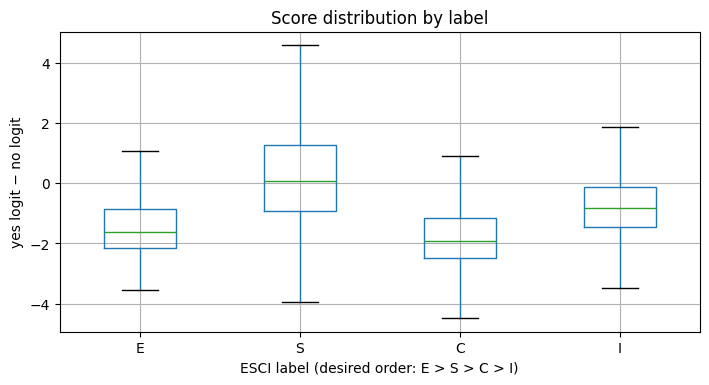

In [5]:
label_summary = (
    enriched.groupby("gold_label", observed=True)
    .agg(
        products=("product_id", "size"),
        mean_score=("ranking_score", "mean"),
        median_score=("ranking_score", "median"),
        top_10_rate=("predicted_rank", lambda values: (values <= TOP_K).mean()),
        mean_rank=("predicted_rank", "mean"),
    )
    .reindex(LABEL_ORDER)
)
display(Markdown("### Aggregate score separation by ESCI label"))
display(
    label_summary.style.format(
        {"mean_score": "{:.3f}", "median_score": "{:.3f}", "top_10_rate": "{:.1%}", "mean_rank": "{:.2f}"}
    )
)

fig, ax = plt.subplots(figsize=(8, 4))
enriched.boxplot(
    column="ranking_score", by="gold_label", positions=range(1, 5), ax=ax, showfliers=False
)
ax.set_xticklabels(LABEL_ORDER)
ax.set_xlabel("ESCI label (desired order: E > S > C > I)")
ax.set_ylabel("yes logit − no logit")
ax.set_title("Score distribution by label")
fig.suptitle("")
plt.show()

## 3. Query-level label ordering

For every query, all differently labeled product pairs are compared. A pair is correct when the product with the higher ESCI grade also has the higher model score. `strict_separation=True` means **every** cross-label pair is correctly separated—not merely that the label means are ordered.

In [6]:
def query_order_statistics(group: pd.DataFrame) -> dict:
    rows = list(group[["gold_label", "ranking_score"]].itertuples(index=False, name=None))
    comparisons = 0
    correct = 0
    worst_inversion_gap = 0.0
    for left_index, (left_label, left_score) in enumerate(rows):
        for right_label, right_score in rows[left_index + 1 :]:
            left_grade = LABEL_GRADE[left_label]
            right_grade = LABEL_GRADE[right_label]
            if left_grade == right_grade:
                continue
            comparisons += 1
            higher_score, lower_score = (
                (left_score, right_score)
                if left_grade > right_grade
                else (right_score, left_score)
            )
            if higher_score > lower_score:
                correct += 1
            else:
                worst_inversion_gap = max(
                    worst_inversion_gap, lower_score - higher_score
                )
    observed_labels = [
        label for label in LABEL_ORDER if label in set(group["gold_label"])
    ]
    label_means = group.groupby("gold_label")["ranking_score"].mean()
    return {
        "query_id": group["query_id"].iloc[0],
        "query": group["query"].iloc[0],
        "candidate_count": len(group),
        "labels_present": "".join(observed_labels),
        "cross_label_pairs": comparisons,
        "pair_order_accuracy": correct / comparisons if comparisons else float("nan"),
        "mean_label_ordered": all(
            label_means[higher] > label_means[lower]
            for higher, lower in zip(observed_labels, observed_labels[1:])
        ),
        "strict_separation": comparisons > 0 and correct == comparisons,
        "worst_inversion_gap": worst_inversion_gap,
    }


def inspection_table(query_ids, max_products_per_query=30):
    columns = [
        "query_id", "query", "predicted_rank", "gold_label",
        "ranking_score", "product_id", "product_title",
        "product_brand", "product_color",
    ]
    selected = enriched[enriched["query_id"].isin(query_ids)].copy()
    selected = selected.sort_values(["query_id", "predicted_rank"])
    return selected.groupby("query_id", sort=False).head(max_products_per_query)[columns]


order_stats = pd.DataFrame(
    query_order_statistics(group)
    for _, group in enriched.groupby("query_id", sort=False)
)
ndcg_column = next(column for column in per_query if column.startswith("ndcg@"))
order_stats = order_stats.merge(
    per_query[["query_id", ndcg_column]], on="query_id", how="left"
)

display(
    pd.DataFrame(
        {
            "value": {
                "mean same-query pair-order accuracy": order_stats["pair_order_accuracy"].mean(),
                "queries with strict cross-label separation": order_stats["strict_separation"].mean(),
                "queries with all four labels": order_stats["labels_present"].eq("ESCI").mean(),
            }
        }
    ).style.format({"value": "{:.2%}"})
)

,value
mean same-query pair-order accuracy,74.38%
queries with strict cross-label separation,7.07%
queries with all four labels,12.80%


## 4. Strong examples: correct `E > S > C > I` ordering

No evaluated query containing all four labels achieved perfect separation of every individual cross-label product pair. The following are therefore the strongest honest examples: all four **label means** follow `E > S > C > I`, and the queries are ranked by their individual pair-order accuracy. Products with the same label are intentionally unconstrained because the training data gives no preferred order within a label.

In [7]:
good_queries = (
    order_stats[
        order_stats["mean_label_ordered"] & order_stats["labels_present"].eq("ESCI")
    ]
    .sort_values(
        ["pair_order_accuracy", ndcg_column, "candidate_count"],
        ascending=[False, False, False],
    )
    .head(5)
)
display(good_queries.reset_index(drop=True))
display(inspection_table(good_queries["query_id"].tolist()))

,query_id,query,candidate_count,labels_present,cross_label_pairs,pair_order_accuracy,mean_label_ordered,strict_separation,worst_inversion_gap,ndcg@10
0,92292,shark pencil,16,ESCI,77,1.000000,True,True,0.000000,1.000000
1,97047,sportsman stock exhaust,16,ESCI,78,1.000000,True,True,0.000000,1.000000
2,8820,american outdoor grills,16,ESCI,77,0.961039,True,False,1.171875,0.991450
3,85111,quinny buzz stroller,16,ESCI,89,0.955056,True,False,0.406250,0.975787
4,40337,fimibuke,40,ESCI,429,0.941725,True,False,3.890625,1.000000


,query_id,query,predicted_rank,gold_label,ranking_score,product_id,product_title,product_brand,product_color
1532,8820,american outdoor grills,1,E,3.242188,B00VSNEDBA,AOG American Outdoor Grill 30NBT-00SP T-Series 30 inch Built-in Natural Gas Grill,American Outdoor Grills,Stainless Steel
1528,8820,american outdoor grills,2,E,3.179688,B07B7Q51K2,AOG American Outdoor Grill T-series 36-inch 3-burner Built-in Natural Gas Grill - 36nbt-00sp,American Outdoor Grills,Stainless Steel
1533,8820,american outdoor grills,3,E,3.015625,B00Q6MHIW4,AOG American Outdoor Grill 36NBL-00SP L-Series 36 inch Built-in Natural Gas Grill,AOG,Stainless Steel
1530,8820,american outdoor grills,4,E,1.335938,B01HITNEEE,"American Gourmet 463773717 Char-Broil Classic 360 3-Burner Liquid Propane Gas Grill, Black",AMERICAN GOURMET,Black
1526,8820,american outdoor grills,5,S,0.976562,B07B8SPXTG,Blaze Premium LTE 32-Inch 4-Burner Built-in Propane Gas Grill with Rear Infrared Burner & Grill Lights - BLZ-4LTE2-LP,Blaze,Stainless Steel
1531,8820,american outdoor grills,6,E,0.468750,B01ENV3UDA,"Royal Gourmet GD401 Portable Propane Gas Grill and Griddle Combo with Side Table | 4-Burner, Folding Legs,Versatile,...",Royal Gourmet,Black
1525,8820,american outdoor grills,7,E,-0.195312,B0822BKLR4,"Traeger Grills Ironwood 650 Wood Pellet Grill and Smoker with Alexa and WiFIRE Smart Home Technology, Black",Traeger,Black
1529,8820,american outdoor grills,8,C,-0.390625,B074CKPPT8,American Outdoor Grill - Automatic Timer Safety Shut-Off Valve - 3 Hour,American Outdoor Grill,None
1534,8820,american outdoor grills,9,C,-1.335938,B004W4X930,American Outdoor Grills Replacement Burner,American Outdoor Grills,None
1524,8820,american outdoor grills,10,C,-1.703125,B07B8SYB35,AOG American Outdoor Grill Cover for 36-Inch Freestanding Gas Grills - CC36-D,AOG,Black


## 5. Strongest score/label inversions

For each query, this finds the single largest inversion: a lower-grade product scoring above a higher-grade product. Large gaps are useful review targets, but the table alone cannot determine whether the model or annotation is wrong.

In [8]:
def worst_inversion(group: pd.DataFrame):
    best = None
    rows = list(group.to_dict("records"))
    for left_index, left in enumerate(rows):
        for right in rows[left_index + 1 :]:
            if left["grade"] == right["grade"]:
                continue
            higher, lower = (left, right) if left["grade"] > right["grade"] else (right, left)
            gap = lower["ranking_score"] - higher["ranking_score"]
            if gap <= 0 or (best is not None and gap <= best["inversion_gap"]):
                continue
            best = {
                "query_id": higher["query_id"],
                "query": higher["query"],
                "inversion_gap": gap,
                "higher_label": higher["gold_label"],
                "higher_score": higher["ranking_score"],
                "higher_title": higher["product_title"],
                "lower_label": lower["gold_label"],
                "lower_score": lower["ranking_score"],
                "lower_title": lower["product_title"],
            }
    return best


inversions = pd.DataFrame(
    inversion
    for _, group in enriched.groupby("query_id", sort=False)
    if (inversion := worst_inversion(group)) is not None
)
inversions = inversions.merge(
    per_query[["query_id", ndcg_column]], on="query_id", how="left"
)
worst_inversions = inversions.sort_values(
    ["inversion_gap", ndcg_column], ascending=[False, True]
).head(12)
display(worst_inversions.reset_index(drop=True))

display(Markdown("### Full rankings for the five largest inversions"))
display(inspection_table(worst_inversions["query_id"].head(5).tolist()))

,query_id,query,inversion_gap,higher_label,higher_score,higher_title,lower_label,lower_score,lower_title,ndcg@10
0,115194,youth jordan 1,6.281250,S,-1.664062,"Nike Unisex-Kid's Team Hustle D 9 Pre School Basketball Shoe, Black/Metallic Gold-White, 1.5Y Regular US Little Kid",I,4.617188,Jordan Youth Air Jordan 1 Mid GS 554725 069 Chicago Black Toe - Size 4Y,0.570674
1,1957,128oz lube,6.218750,E,-2.968750,DrinkTanks 128 oz Vacuum Insulated Stainless Steel Beer Growler,S,3.250000,"Wet Original Water Based Sex Lube 128 Ounce Premium Personal Lubricant, Long Lasting Formula for Condom Safe Vegan P...",0.945094
2,12655,baking pans 10x15,6.015625,S,-1.804688,"Nordic Ware Quarter Sheet, 2 Pack, Natural",C,4.210938,"Fat Daddio's Sheet Cake Pan, 10 x 15 x 3 Inch, Silver",0.747729
3,83260,pride mobility scooter,5.281250,E,-2.375000,Battery Pack for Pride Go-Go Elite Traveller Plus & Go-Go Sport Scooters,S,2.906250,Go-Go Ultra X 2.0 3-Wheel Travel Scooter,1.000000
4,70411,monk fruit sweetener without erythritol,5.039062,S,-3.242188,"SmartyPants Women's Formula Gummy Vitamins: Gluten Free, Multivitamin, CoQ10, Folate (Methylfolate), Vitamin K2, Vit...",I,1.796875,"LLINEA MONK FRUIT - Approx. 200 Servings Per Bottle - 6 Drops = 1 Tsp of Sugar - Sweeten Coffee, Tea, Smoothies, & M...",0.914857
5,76433,otterbox 6se phone case,5.007812,C,-2.367188,"AlphaCell Holster Belt Clip Replacement Compatible with OtterBox Defender Series Case for Apple iPhone 5, iPhone 5s,...",I,2.640625,"Otterbox Symmetry Series Case for Iphone 6/6s (4.7"" Version) - Retail Packaging - Prevail (Coral/Gunmetal Grey)",0.779908
6,110930,white and blue fishing reel,4.906250,S,-2.273438,"Reel Grip 1144 Reel Handle Cover, Patriotic Tie Dye Finish",C,2.632812,"Okuma Fishing TU-702-50 Tundra Combo Spinning Reel (Large, White/Blue)",0.696381
7,44473,garmin 530,4.867188,E,-1.914062,TUSITA Case Compatible with Garmin Edge 530 - Silicone Protective Cover - Cycling GPS Computer Accessories,S,2.953125,"Garmin Edge 530 Performance GPS Cycling/Bike Computer (Mountain Bike Bundle) with Fitness & Wellness Suite, Tempered...",0.843476
8,87942,roasting pan for 30 lb turkey,4.835938,E,-1.289062,"Viking 3-Ply Stainless Steel Oval Roaster with Metal Induction Lid and Rack, 8.5 Quart",C,3.546875,"Reynolds Kitchens Turkey Size Roaster Pan, Holds Up to 30lbs, 1 Count",0.640291
9,36476,easieeaters curved utensils right handed without shields,4.632812,E,-2.929688,"Crimson Trace LG-105 Lasergrips with Red Laser, Heavy Duty Construction and Instinctive Activation for S&W J-Frame R...",S,1.703125,Easie Eaters Fork and Spoon(Style=Left Handed),0.824337


### Full rankings for the five largest inversions

,query_id,query,predicted_rank,gold_label,ranking_score,product_id,product_title,product_brand,product_color
747,1957,128oz lube,1,E,3.968750,B000C14OOK,"TriFlow Superior lube, 128oz (1 Gallon) ORM-D",TriFlow,Black
745,1957,128oz lube,2,E,3.679688,B002R5BCYE,"ID Lubricants Glide 128 Fl Oz Natural Feel Water-Based Personal Lubricant, Clear, 128 Oz",ID Lubricants,Clear
741,1957,128oz lube,3,E,3.617188,B06WRV546X,Spunk Lube Hybrid (128 Ounce (1 Gallon)),Spunk,None
739,1957,128oz lube,4,E,3.476562,B077SPJN4B,"Spunk Pure Silicone Lubricant, (128 Ounce)",Spunk,None
752,1957,128oz lube,5,S,3.250000,B001H0AXRW,"Wet Original Water Based Sex Lube 128 Ounce Premium Personal Lubricant, Long Lasting Formula for Condom Safe Vegan P...",WET,Translucent
...,...,...,...,...,...,...,...,...,...
15149,115194,youth jordan 1,12,S,-1.562500,B00C0OZGP8,"Nike Boy's Team Hustle D 8 (PS) Basketball Shoe, Black/Metallic Silver - White, 1.5Y Regular US Little Kid",Nike,Black/Metallic Silver - White
15145,115194,youth jordan 1,13,S,-1.664062,B07NM27TFN,"Nike Unisex-Kid's Team Hustle D 9 Pre School Basketball Shoe, Black/Metallic Gold-White, 1.5Y Regular US Little Kid",Nike,Black/Metallic Gold-white
15146,115194,youth jordan 1,14,I,-2.164062,B07D9BML9Y,"adidas baby girls Adissage Slide, Black/White/Black, 5 Big Kid US",adidas,Black/White/Black
15148,115194,youth jordan 1,15,I,-2.218750,B0714BNRWC,adidas Men's Adilette Shower Slides Black/White/White 7,adidas,Black/White/White


## 6. Curated annotation-quality review cases

These queries were selected after inspecting the low-NDCG tail. Several look malformed, encode exclusions/negation, or appear to have labels that do not match the literal query. They are especially useful for separating ranking failures from dataset noise.

In [9]:
CURATED_REVIEW_NOTES = {
    606: "Malformed query; several E labels appear unrelated to the literal text.",
    33810: "Ambiguous intent: channel/subscription wording versus physical Disney products.",
    74074: "Natural-language complaint/non-shopping query with surprising E annotations.",
    55882: "Explicit 'without cross' constraint; inspect whether labels honor the exclusion.",
    20080: "Explicit 'without envelopes' constraint; useful negation/constraint case.",
}
curated_ids = [query_id for query_id in CURATED_REVIEW_NOTES if query_id in set(enriched["query_id"])]
curated_summary = order_stats[order_stats["query_id"].isin(curated_ids)].copy()
curated_summary["review_reason"] = curated_summary["query_id"].map(CURATED_REVIEW_NOTES)
display(curated_summary.sort_values(ndcg_column).reset_index(drop=True))
display(inspection_table(curated_ids))

,query_id,query,candidate_count,labels_present,cross_label_pairs,pair_order_accuracy,mean_label_ordered,strict_separation,worst_inversion_gap,ndcg@10,review_reason
0,606,0zo not bit,33,EI,116,0.310345,False,False,0.914062,0.000000,Malformed query; several E labels appear unrelated to the literal text.
1,33810,disney plus channel,16,EI,15,0.133333,False,False,0.281250,0.000000,Ambiguous intent: channel/subscription wording versus physical Disney products.
2,55882,jesus without cross,40,ESI,179,0.564246,False,False,1.648438,0.000000,Explicit 'without cross' constraint; inspect whether labels honor the exclusion.
3,74074,no it's not his bike,16,EI,28,0.142857,False,False,2.953125,0.000000,Natural-language complaint/non-shopping query with surprising E annotations.
4,20080,brown notecards without envelopes,40,ESCI,483,0.571429,False,False,1.023438,0.335852,Explicit 'without envelopes' constraint; useful negation/constraint case.


,query_id,query,predicted_rank,gold_label,ranking_score,product_id,product_title,product_brand,product_color
125,606,0zo not bit,1,I,-1.679688,B087C1R9QW,"YAMAY Smart Watch, Watches for Men Women Fitness Tracker Blood Pressure Monitor Blood Oxygen Meter Heart Rate Monito...",YAMAY,Pink
126,606,0zo not bit,2,I,-1.843750,B08CFSZLQ4,Google Pixel 4a - New Unlocked Android Smartphone - 128 GB of Storage - Up to 24 Hour Battery - Just Black,Google,Just Black
129,606,0zo not bit,3,I,-1.914062,B07YWRXVP6,"Willful Smart Watch for Android Phones and iOS Phones Compatible iPhone Samsung, IP68 Swimming Waterproof Smartwatch...",Willful,None
124,606,0zo not bit,4,I,-2.031250,B084D89DBF,Moto G Power | 3-Day Battery1 | Unlocked | Made for US by Motorola | 4/64GB | 16MP Camera | 2020 | Black,Motorola,Black
138,606,0zo not bit,5,I,-2.039062,B00GMXFK3G,"DEWALT Screwdriver Bit Set, Impact Ready, FlexTorq, 40-Piece (DWA2T40IR)",DEWALT,"Black/Silver IMPACT READY FlexTorq Screw Driving Set, 40-Piece"
...,...,...,...,...,...,...,...,...,...
9899,74074,no it's not his bike,12,I,-3.375000,B01LY3QXGP,"Mancro Laptop Backpack, Business Water Resistant Laptop bag Backpack Gift for Men Women with USB Charging Port, Anti...",Mancro,Austere Grey
9900,74074,no it's not his bike,13,I,-3.382812,B01IP0DXGE,"I Love To Wrap Both My Hands Around It And Swallow, Funny Stemless Wine Glass, Perfect For Bachelorette Parties, Bri...",C & M Personal Gifts,Clear
9891,74074,no it's not his bike,14,I,-3.437500,B078WZSGGW,"Yes, they're Natural 20 d20 dice funny RPG gamer T Shirt",Shirts for Salty Gamers,Black
9905,74074,no it's not his bike,15,I,-3.570312,B075X2JJNT,Funcle Gift for Uncle Graphic Novelty Sarcastic Funny T Shirt XL Black,Feelin Good Tees,Black


## 7. Manual review sheet

Use this table to record a judgment for each suspicious query. Suggested values are `model_error`, `label_error`, `ambiguous`, and `insufficient_product_text`. The optional export remains commented out so running the notebook does not silently create another artifact.

In [10]:
review_query_ids = list(
    dict.fromkeys(worst_inversions["query_id"].head(12).tolist() + curated_ids)
)
review_sheet = (
    order_stats[order_stats["query_id"].isin(review_query_ids)]
    [["query_id", "query", ndcg_column, "pair_order_accuracy", "worst_inversion_gap"]]
    .sort_values([ndcg_column, "worst_inversion_gap"], ascending=[True, False])
    .copy()
)
review_sheet["reviewer_judgment"] = ""
review_sheet["reviewer_notes"] = ""
display(review_sheet.reset_index(drop=True))

# Optional after filling the fields above:
# review_sheet.to_csv(PROJECT_ROOT / "run_results/qwen_esci_v1_manual_review.csv", index=False)

,query_id,query,ndcg@10,pair_order_accuracy,worst_inversion_gap,reviewer_judgment,reviewer_notes
0,74074,no it's not his bike,0.000000,0.142857,2.953125,,
1,55882,jesus without cross,0.000000,0.564246,1.648438,,
2,606,0zo not bit,0.000000,0.310345,0.914062,,
3,33810,disney plus channel,0.000000,0.133333,0.281250,,
4,20080,brown notecards without envelopes,0.335852,0.571429,1.023438,,
5,115194,youth jordan 1,0.570674,0.571429,6.281250,,
6,87942,roasting pan for 30 lb turkey,0.640291,0.482353,4.835938,,
7,110930,white and blue fishing reel,0.696381,0.575758,4.906250,,
8,49233,hario v60 filter,0.732406,0.416667,4.585938,,
9,12655,baking pans 10x15,0.747729,0.710145,6.015625,,


## Takeaways

- Judge the trained run against the unmodified-Qwen baseline produced by `python jobs/submit_train_esci.py --eval-only`; absolute trained metrics alone do not measure improvement.
- Recall@10 should be read relative to its query-specific ceiling, because many ESCI queries have more than 10 relevant candidates.
- Aggregate score means can follow `E > S > C > I` while individual products still overlap substantially. Query-level pair accuracy and inversion examples expose that overlap.
- Do not automatically train harder on the suspicious cases. First classify them as model errors, annotation errors, ambiguous intent, or insufficient product text.